# Noiseless circuits and ITensors evolution match

## Simulation settings

In [2]:
L = 21
J = 5
h = 0.8
lamb = 1

x_basis = False

particle_pair_left_position = L//2 - 3
particle_pair_length = 6

final_time = 5
dt = 0.125
steps = 40

itensors_cutoff = 1e-12

## ITensors simulation

In [ ]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
from juliacall import Main as jl, convert as jlconvert
import numpy as np
import os

overwrite = False

path_to_julia_tn = "../../z2chain/Z2HiggsChainDynamics.jl"
jl.seval(f"include(\"{path_to_julia_tn}\")")
jl.seval("using .Z2HiggsChainDynamics")

filepath = f"Results/tnjulia_z2pairquench_maxt_{final_time}_steps_{steps}_L_{L}_J_{J}_h_{h:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_xbasis_{x_basis}_steps_{steps}_ploteach_{1}_cutoff_{itensors_cutoff}.npy"
if os.path.exists(filepath) and not overwrite:
    itensors_observables = load_site_gauge_observable_matrix(filepath)
else:
    sites = jl.chain_sites(L)
    mpos = jl.all_local_pauli_z(sites)
    itensors_observables = jl.Z2HiggsChainDynamics.particle_pair_quench_simulation(sites, mpos, J, h, lamb, particle_pair_left_position, particle_pair_length, final_time, steps, x_basis, 1, itensors_cutoff)
    itensors_observables = np.array(itensors_observables)
    if overwrite:
        save_site_gauge_observable_matrix(itensors_observables, filepath)

In [ ]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(itensors_observables, cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])

## Qiskit circuit simulation

### Circuits

In [ ]:
from z2chain.circs import string_quench_simulation_circuits_dt
from z2chain.operators import local_pauli_x, local_pauli_z, postselection_operators
from cobos.tokens import ibm_token, group_instance, group_instance2
from utils.hexec import get_backend_best_qubit_chain
from utils.plotting import plot_circuit_arr_depth
from qiskit_aer import AerSimulator

simulator = AerSimulator(method="matrix_product_state")

optimization_level = 3
circs_args = (L, J, h, lamb, final_time, dt, steps, simulator, optimization_level, None, particle_pair_left_position, particle_pair_length, None, x_basis, False)
circuits = string_quench_simulation_circuits_dt(*circs_args)
observable_generating_funcs = [lambda nqubits, i=i: local_pauli_x(nqubits, i) if x_basis else local_pauli_z(nqubits, i) for i in range(2*L-1)]
postselection_operators_func = lambda nqubits: postselection_operators((nqubits+1)//2, x_basis)

plot_circuit_arr_depth(circuits)

### Simulation

In [6]:
from utils.plotting import convert_jobs_to_site_gauge_matrix, load_site_gauge_observable_matrix
from utils.sexec import execute_simulation_estimator_batch

overwrite = False

backend_options = {
    "method": "matrix_product_state",
    "matrix_product_state_max_bond_dimension": None,
    "matrix_product_state_truncation_threshold": itensors_cutoff
}

estimator_options = {
    "default_precision": 0
}

filepath = f"Results/tncirc_z2pairquench_maxt_{final_time}_steps_{steps}_L_{L}_J_{J}_h_{h:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_xbasis_{x_basis}_steps_{steps}_ploteach_{1}_cutoff_{itensors_cutoff}_maxbdim_{backend_options["matrix_product_state_max_bond_dimension"]}.npy"

if os.path.exists(filepath) and not overwrite:
    qiskit_observables = load_site_gauge_observable_matrix(filepath)
else:
    mps_jobs = execute_simulation_estimator_batch(backend_options, estimator_options, circuits, observable_generating_funcs)
    qiskit_observables = convert_jobs_to_site_gauge_matrix(mps_jobs)
    if overwrite:
        save_site_gauge_observable_matrix(qiskit_observables, filepath)

In [ ]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(1 - 2*qiskit_observables, cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])

## Comparison

### Mean error per time

In [ ]:
np.arange(0, steps + 1, (steps)//(4))

In [ ]:
np.arange(0, steps+1, (steps)//(5))

In [ ]:
from utils.plotting import plot_mean_deviations

x_ticks = [
    np.arange(0, steps+1, (steps)//4),
    np.linspace(0, final_time, 5)
]

plot_mean_deviations(itensors_observables, 1 - 2*qiskit_observables, x_label="t", x_ticks=x_ticks)

# Noisy-noiseless comparison

## Simulation options

In [ ]:
import numpy as np

L = 5
params_tuples = [
    (0, 0, 1),
    (5, 0.8, 1),
    (0.8, 5, 1)
]

x_basis = False

particle_position = 2

final_time = 5
dt = 0.15
steps = 34

shots = 100000

print(f"Sampling error ~ {2/np.sqrt(shots)}")

sampler_options = {
    "default_shots": shots,
}

## Ground truth

In [ ]:
from z2chain.exact import singlep_quench_simulation

overwrite = True

ed_observables = []
for J, h, lamb in params_tuples:
    print(f"Parameters: J = {J} / h = {h} / lamb = {lamb}")
    filepath = f"Results/ed_z2_singlep_quench_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_pp_{particle_position}_xbasis_{x_basis}_steps_{steps}_ploteach_{1}.npy"
    this_ed_observables = singlep_quench_simulation(L, J, h, lamb, particle_position, dt, steps, filepath=filepath, overwrite=overwrite, print_mode=True)
    ed_observables.append(this_ed_observables)
    print("")

In [ ]:
from z2chain.plotting import x_t_separated_plot

for i, (J, h, lamb) in enumerate(params_tuples):
    x_t_separated_plot(1 - 2*ed_observables[i], cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1], )

## Different GDD strategies

### Noisy simulator options

In [14]:
from cobos.tokens import ibm_token, group_instance, group_instance2
# from fradm.tokens import ibm_token, group_instance
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_aer.noise import NoiseModel
from qiskit_aer import AerSimulator

channel = "ibm_quantum"
device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
# device = "ibm_marrakesh"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)
simulator = AerSimulator.from_backend(backend)

### No GDD

#### Circuits

In [ ]:
from z2chain.operators import local_pauli_x, local_pauli_z, postselection_operators
from z2chain.circs import singlep_quench_simulation_and_odr_circs
from utils.hexec import get_backend_best_qubit_chain
from utils.plotting import plot_circuit_arr_depth

g_func = None
layout = get_backend_best_qubit_chain(backend, 2*L-1)

no_gdd_circuits = []
no_gdd_odr_circuits = []

for J, h, lamb in params_tuples:
    print(f"\rParameters: J = {J} / h = {h} / lamb = {lamb}".ljust(100), end="")
    circuits_args = (L, J, h, lamb, particle_position, final_time, dt, steps, simulator, optimization_level, g_func, layout, x_basis, False)
    this_sim_circuits, this_odr_circuits = singlep_quench_simulation_and_odr_circs(*circuits_args)
    no_gdd_circuits.append(this_sim_circuits)
    no_gdd_odr_circuits.append(this_odr_circuits)
print("\rDone".ljust(1000))

observable_generating_funcs = [lambda nqubits, i=i: local_pauli_x(nqubits, i) if x_basis else local_pauli_z(nqubits, i) for i in range(2*L-1)]
postselection_operators_func = lambda nqubits: postselection_operators((nqubits+1)//2, x_basis)

#### Simulation

In [ ]:
from utils.postselection_multithreaded import initialize_postselection, multiprocess_get_postselected_recovered_samples_dicts, multiprocess_measure_diagonal_observables, pauli_to_str
from utils.odr import compute_depolarizing_probability, renormalize_observable
import pickle
import os

overwrite = False
confidence = None

flip_threshold = None

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(2*L-1, postselection_operators_func, observable_generating_funcs)

clean_observables = []
sim_observables = []
odr_observables = []
raw_observables = []

for i, (J, h, lamb) in enumerate(params_tuples):
    print(f"\rSimulating parameters: J = {J} / h = {h} / lamb = {lamb}".ljust(100), end="")
    filename = f"Results/noisy_z2singlep_quench_no_gdd_samples_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_pp_{particle_position}_xbasis_{x_basis}_steps_{steps}_ploteach_{1}_shots_{shots}.pkl"
    if os.path.exists(filename) and not overwrite:
        with open(filename, "rb") as f:
            to_load_samples_dicts = pickle.load(f)
        this_samples_dicts = to_load_samples_dicts[:len(to_load_samples_dicts)//2]
        this_odr_samples_dicts = to_load_samples_dicts[len(to_load_samples_dicts)//2:]
    else:
        this_samples_dicts = []
        this_odr_samples_dicts = []
        for j in range(len(no_gdd_circuits[i])):
            this_time_samples_dict = simulator.run(no_gdd_circuits[i][j], shots=shots).result().get_counts()
            this_time_odr_samples_dict = simulator.run(no_gdd_odr_circuits[i][j], shots=shots).result().get_counts()
            this_samples_dicts.append(this_time_samples_dict)
            this_odr_samples_dicts.append(this_time_odr_samples_dict)
        if overwrite or not os.path.exists(filename):
            with open(filename, "wb") as f:
                pickle.dump(this_samples_dicts + this_odr_samples_dicts, f)

    this_samples_dicts = np.array(this_samples_dicts)
    this_odr_samples_dicts = np.array(this_odr_samples_dicts)

    postselection_ops_to_str = [pauli_to_str(op) for op in postselection_ops]
    to_remove_str = "I"*(2*L-3) + "ZZ"
    to_remove_str_ind = postselection_ops_to_str.index(to_remove_str[::-1])
    flipped_syndromes = np.zeros(len(postselection_ops_to_str), dtype=int)
    flipped_syndromes[to_remove_str_ind] = 1

    postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(this_samples_dicts, postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)
    postselected_odr_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(this_odr_samples_dicts, postselection_ops, flip_threshold, recovery_function=None)

    sim_observables.append(multiprocess_measure_diagonal_observables(postselected_samples_dicts, diagonal_observables))
    raw_observables.append(multiprocess_measure_diagonal_observables(this_samples_dicts, diagonal_observables))
    odr_observables.append(multiprocess_measure_diagonal_observables(postselected_odr_samples_dicts, diagonal_observables))
    clean_observables = np.zeros_like(sim_observables)
    for i in range(len(sim_observables)):
        p_arr = compute_depolarizing_probability(odr_observables[i], 1, 0, no_gdd_odr_circuits[i][1].num_qubits)
        clean_observables[i] = renormalize_observable(sim_observables[i], p_arr, 0, no_gdd_circuits[i][1].num_qubits, observable_range=(-1, 1), expected_observable_arr=1)

#### Observables

In [ ]:
from z2chain.plotting import x_t_separated_plot

for i in range(len(clean_observables)):
    x_t_separated_plot(clean_observables[i], cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])

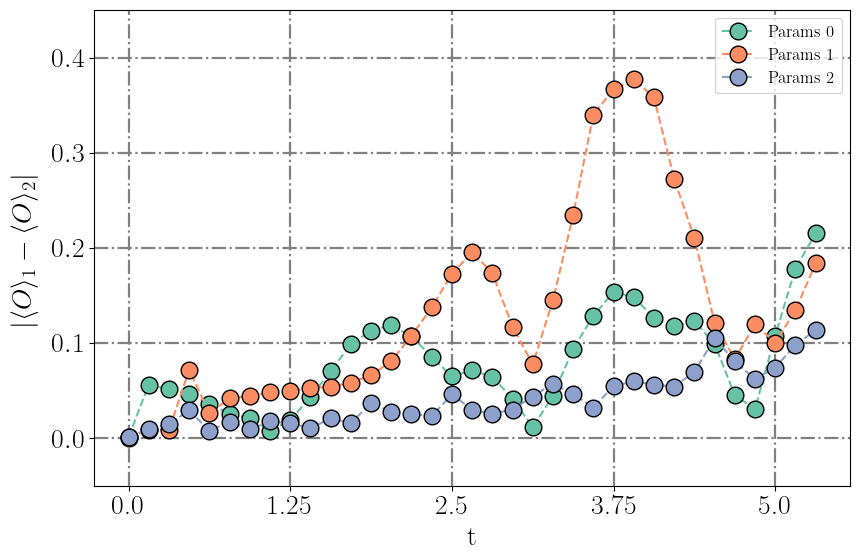

In [21]:
from utils.plotting import plot_mean_deviations
import numpy as np

x_ticks = [
    np.arange(0, steps+1, (steps)//4),
    np.linspace(0, final_time, 5)
]

y_lim = [-0.05, 0.45]

labels = [rf"$m = {J:.2f}$ / $g = {h:.2f}$ / \lambda = {lamb:.2f}$" for J, h, lamb in params_tuples]

plot_mean_deviations(clean_observables, 1-2*np.array(ed_observables), x_label="t", x_ticks=x_ticks, y_lim=y_lim)

### GDD

#### Circuits

In [ ]:
from z2chain.operators import local_pauli_x, local_pauli_z, postselection_operators
from z2chain.circs import singlep_quench_simulation_and_odr_circs
from z2chain.gdd import from_matrix, zero_mean_gdd_matrix
from utils.hexec import get_backend_best_qubit_chain
from utils.plotting import plot_circuit_arr_depth
from functools import partial

g_func = partial(from_matrix, matrix=zero_mean_gdd_matrix(L, steps))
layout = get_backend_best_qubit_chain(backend, 2*L-1)

gdd_circuits = []
gdd_odr_circuits = []

for J, h, lamb in params_tuples:
    print(f"\rParameters: J = {J} / h = {h} / lamb = {lamb}".ljust(100), end="")
    circuits_args = (L, J, h, lamb, particle_position, final_time, dt, steps, simulator, optimization_level, g_func, layout, x_basis, False)
    this_sim_circuits, this_odr_circuits = singlep_quench_simulation_and_odr_circs(*circuits_args)
    gdd_circuits.append(this_sim_circuits)
    gdd_odr_circuits.append(this_odr_circuits)
print("\rDone".ljust(1000))

observable_generating_funcs = [lambda nqubits, i=i: local_pauli_x(nqubits, i) if x_basis else local_pauli_z(nqubits, i) for i in range(2*L-1)]
postselection_operators_func = lambda nqubits: postselection_operators((nqubits+1)//2, x_basis)

#### Simulation

In [ ]:
from utils.postselection_multithreaded import initialize_postselection, multiprocess_get_postselected_recovered_samples_dicts, multiprocess_measure_diagonal_observables, pauli_to_str
from utils.odr import compute_depolarizing_probability, renormalize_observable
import pickle
import os

overwrite = False
confidence = None

flip_threshold = None

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(2*L-1, postselection_operators_func, observable_generating_funcs)

clean_observables = []
sim_observables = []
odr_observables = []
raw_observables = []

for i, (J, h, lamb) in enumerate(params_tuples):
    print(f"\rSimulating parameters: J = {J} / h = {h} / lamb = {lamb}".ljust(100), end="")
    filename = f"Results/noisy_z2singlep_quench_gdd_samples_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_pp_{particle_position}_xbasis_{x_basis}_steps_{steps}_ploteach_{1}_shots_{shots}.pkl"
    if os.path.exists(filename) and not overwrite:
        with open(filename, "rb") as f:
            to_load_samples_dicts = pickle.load(f)
        this_samples_dicts = to_load_samples_dicts[:len(to_load_samples_dicts)//2]
        this_odr_samples_dicts = to_load_samples_dicts[len(to_load_samples_dicts)//2:]
    else:
        this_samples_dicts = []
        this_odr_samples_dicts = []
        for j in range(len(no_gdd_circuits[i])):
            this_time_samples_dict = simulator.run(gdd_circuits[i][j], shots=shots).result().get_counts()
            this_time_odr_samples_dict = simulator.run(gdd_odr_circuits[i][j], shots=shots).result().get_counts()
            this_samples_dicts.append(this_time_samples_dict)
            this_odr_samples_dicts.append(this_time_odr_samples_dict)
        if overwrite or not os.path.exists(filename):
            with open(filename, "wb") as f:
                pickle.dump(this_samples_dicts + this_odr_samples_dicts, f)

    this_samples_dicts = np.array(this_samples_dicts)
    this_odr_samples_dicts = np.array(this_odr_samples_dicts)

    postselection_ops_to_str = [pauli_to_str(op) for op in postselection_ops]
    to_remove_str = "I"*(2*L-3) + "ZZ"
    to_remove_str_ind = postselection_ops_to_str.index(to_remove_str[::-1])
    flipped_syndromes = np.zeros(len(postselection_ops_to_str), dtype=int)
    flipped_syndromes[to_remove_str_ind] = 1

    postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(this_samples_dicts, postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)
    postselected_odr_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(this_odr_samples_dicts, postselection_ops, flip_threshold, recovery_function=None)

    sim_observables.append(multiprocess_measure_diagonal_observables(postselected_samples_dicts, diagonal_observables))
    raw_observables.append(multiprocess_measure_diagonal_observables(this_samples_dicts, diagonal_observables))
    odr_observables.append(multiprocess_measure_diagonal_observables(postselected_odr_samples_dicts, diagonal_observables))
    clean_observables = np.zeros_like(sim_observables)
    for i in range(len(sim_observables)):
        p_arr = compute_depolarizing_probability(odr_observables[i], 1, 0, gdd_odr_circuits[i][1].num_qubits)
        clean_observables[i] = renormalize_observable(sim_observables[i], p_arr, 0, gdd_circuits[i][1].num_qubits, observable_range=(-1, 1), expected_observable_arr=1)

#### Observables

In [ ]:
from z2chain.plotting import x_t_separated_plot

for i in range(len(clean_observables)):
    x_t_separated_plot(clean_observables[i], cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])

In [ ]:
from utils.plotting import plot_mean_deviations
import numpy as np

x_ticks = [
    np.arange(0, steps+1, (steps)//4),
    np.linspace(0, final_time, 5)
]

y_lim = [-0.05, 0.45]

# labels = [rf"$m = {J:.2f}$ / $g = {h:.2f}$ / \lambda = {lamb:.2f}$" for J, h, lamb in params_tuples]

plot_mean_deviations(clean_observables, 1-2*np.array(ed_observables), x_label="t", x_ticks=x_ticks, y_lim=y_lim)

Note: GDD makes us loose contrast